# Sri Lankan Used Vehicle Listing Price Prediction
**MSc Applied Machine Learning — class activity**

## 1. Problem statement and objectives
This activity compares Random Forest and XGBoost for predicting the continuous target
`Price` from vehicle and listing details. The aim is to compare prediction errors,
examine data quality and demonstrate both models in a Streamlit dashboard.

The original experiment was completed in Colab. Its notebook and outputs are preserved
in `archive/ML_activity_colab_original.ipynb`. The final experiment excludes redundant
mileage and keeps the original data split and model parameters.

Running this notebook evaluates the saved models. `RETRAIN` and `EXPORT_RETRAINED` are
`False` by default. A new training run should be treated as a separate experiment;
optional exports use `models/retrained/` and do not replace the submitted models.


In [1]:
import sys, json, hashlib, time, platform
from pathlib import Path
import numpy as np
import pandas as pd
import sklearn
import xgboost
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ROOT = Path.cwd()
if not (ROOT / "vehicle_utils.py").exists():
    raise FileNotFoundError("Open the notebook with the project root as the working directory.")
from vehicle_utils import FEATURES, REFERENCE, REPORTED_RESULTS, load_models

RETRAIN = False  # Leave disabled when evaluating the submitted models.
EXPORT_RETRAINED = False  # Optional exports use a separate directory.
MODEL_PATHS = [ROOT / "models" / name for name in
               ["random_forest_pipeline.pkl", "xgboost_pipeline.pkl"]]
def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()
original_hashes = {path.name: sha256(path) for path in MODEL_PATHS}
print("Python:", platform.python_version())
print("pandas:", pd.__version__, "NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__, "XGBoost:", xgboost.__version__)
print("Retraining:", RETRAIN)

Python: 3.12.10
pandas: 2.2.3 NumPy: 2.1.3
scikit-learn: 1.6.1 XGBoost: 3.4.1
Retraining: False


## 2. Dataset description and source
The data comes from Prasad Nirmal's [SriLankan Vehicle(Car) Price Dataset](https://www.kaggle.com/datasets/prasadnirmal/srilankan-second-vehiclecar-price-dataset), version 3.
It contains 9,788 listings and 17 columns, covering 3 December 2024 to 5 February 2025.
The source describes listings collected from ikman.lk and Riyasewana.com.

The dataset is suitable for this regression task because it includes prices alongside
numeric vehicle details and categorical attributes such as brand, fuel type and town.
It also allows investigation of missing values, duplicate listings and unusual patterns.

Kaggle metadata checked on 9 October 2026 states an MIT license and describes Price as
LKR, but does not explain the scale of values such as 44.50. Calculations therefore use
original dataset units without a rupee or lakh conversion. The CSV is excluded from Git;
the README explains how to obtain it. Underlying marketplace rights may still apply.


In [2]:
CSV_PATH = ROOT / "data" / "car_price_dataset.csv"
if not CSV_PATH.exists():
    raise FileNotFoundError("Download Kaggle version 3 to data/car_price_dataset.csv; see README.")
df = pd.read_csv(CSV_PATH)
print("CSV SHA256:", sha256(CSV_PATH))
print("Shape:", df.shape)
assert df.shape == (9788, 17), "Dataset differs from the recorded experiment; investigate before proceeding."
display(df.head())

CSV SHA256: 4208d2673cf4d9c8d3d6042dc8a1b97004671812441975f5879550059fbce1ab
Shape: (9788, 17)


,Unnamed: 0,Brand,Model,YOM,Engine (cc),Gear,Fuel Type,Millage(KM),Town,Date,Leasing,Condition,AIR CONDITION,POWER STEERING,POWER MIRROR,POWER WINDOW,Price
0,0,AUDI,A1,2016,990.0,Automatic,Petrol,99000.0,Gampaha,2025-02-05,No Leasing,USED,Available,Available,Available,Available,100.0
1,1,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2025-01-14,No Leasing,USED,Available,Available,Available,Available,97.0
2,2,AUDI,A1,2018,1000.0,Automatic,Petrol,77000.0,Dehiwala-Mount-Lavinia,2025-01-23,No Leasing,USED,Available,Available,Available,Available,98.5
3,3,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Negombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,107.0
4,4,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,99.5


## 3. Exploratory Data Analysis (EDA)
The summary tables and plots describe missing values, category frequencies, listing
dates and the price distribution. High-priced vehicles are retained so that evaluation
reflects the full price range. EDA uses the full dataset, as in the original experiment;
imputation and encoding are fitted only on training data.


,Type,Missing,Unique
Unnamed: 0,int64,0,9788
Brand,object,0,50
Model,object,0,1555
YOM,int64,0,62
Engine (cc),float64,0,278
Gear,object,0,2
Fuel Type,object,0,4
Millage(KM),float64,0,62
Town,object,0,107
Date,object,0,65


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,9788.0,4893.758991,2826.028988,0.00,2446.75,4893.5,7341.25,9788.0
YOM,9788.0,2006.759093,9.831574,1956.00,2001.00,2009.0,2015.00,2024.0
Engine (cc),9788.0,1260.442358,403.769059,573.00,1000.00,1300.0,1500.00,4800.0
Millage(KM),9788.0,200649.979567,108147.314860,11000.00,110000.00,176000.0,264000.00,759000.0
Price,9788.0,53.464275,43.625049,2.65,26.25,43.0,69.75,790.0


,count,unique,top,freq
Brand,9788,50,TOYOTA,3089
Model,9788,1555,ALTO,392
Gear,9788,2,Automatic,6305
Fuel Type,9788,4,Petrol,7866
Town,9788,107,Colombo,1038
Date,9788,65,2025-02-05,645
Leasing,9788,2,No Leasing,9384
Condition,9788,2,USED,9694
AIR CONDITION,9788,2,Available,9590
POWER STEERING,9788,2,Available,8918


Listing dates: 2024-12-03 00:00:00 to 2025-02-05 00:00:00 invalid: 0


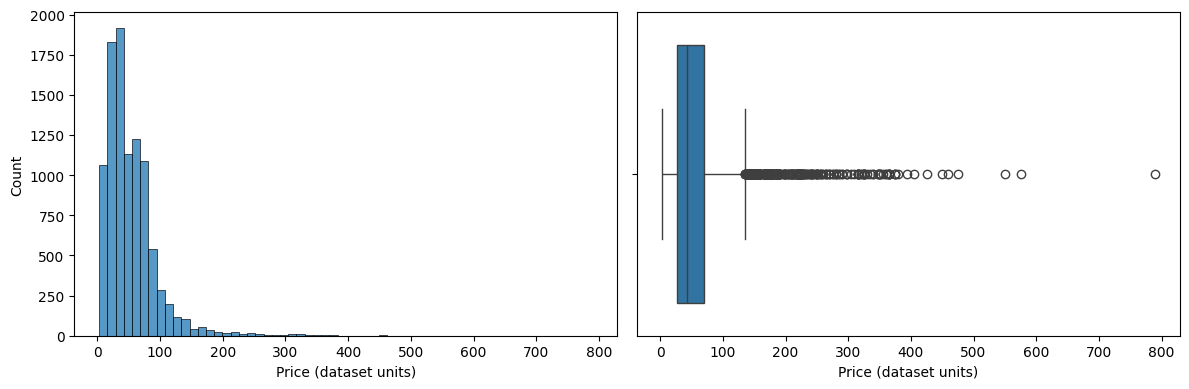

,Brand,Model,YOM,Price
8417,TOYOTA,LEXUS 600HL,2011,790.0
138,BMW,740LE M SPORT,2016,575.0
1776,MERCEDES-BENZ,S400 LONG WHEEL BASE,2015,550.0
55,AUDI,Q4,2024,475.0
133,BMW,530I M SPORT,2017,460.0
109,BMW,430I GRAN COUPE,2017,450.0
153,BMW,M SPORT,2018,425.0
1733,MERCEDES-BENZ,E200,2016,405.0
159,BYD,SEAL,2024,394.5
148,BMW,G30 530I,2017,380.0


In [3]:
display(pd.DataFrame({"Type": df.dtypes.astype(str), "Missing": df.isna().sum(),
                      "Unique": df.nunique()}))
display(df.describe(include="number").T)
display(df.describe(include="object").T)
dates = pd.to_datetime(df["Date"], errors="coerce")
print("Listing dates:", dates.min(), "to", dates.max(), "invalid:", dates.isna().sum())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Price"], bins=60, ax=axes[0])
sns.boxplot(x=df["Price"], ax=axes[1])
for ax in axes:
    ax.set_xlabel("Price (dataset units)")
plt.tight_layout(); plt.show()
display(df.nlargest(10, "Price")[["Brand", "Model", "YOM", "Price"]])

## 4. Data quality investigation
The exported index identifies rows rather than vehicles and masks duplicate listings.
After dropping it, 18 exact duplicates are removed. The mileage column, named
`Millage(KM)` in the CSV, is then checked against `(2025 - YOM) * 11000` for every
cleaned record. All 9,770 records match, so mileage provides no independent odometer
information. This establishes redundancy, not target leakage by itself.


In [4]:
print("Duplicates with exported index:", df.duplicated().sum())
df_work = df.drop(columns=["Unnamed: 0"])
print("Duplicates without exported index:", df_work.duplicated().sum())
df_clean = df_work.drop_duplicates().reset_index(drop=True)
assert len(df_clean) == 9770
assert len(df_work) - len(df_clean) == 18
matches = np.isclose(df_clean["Millage(KM)"], (2025 - df_clean["YOM"]) * 11000)
print("Mileage formula matches:", matches.sum(), "/", len(matches))
assert matches.all()
assert df_clean["Price"].notna().all() and (df_clean["Price"] > 0).all()
display(df_clean[["YOM", "Millage(KM)", "Price"]].corr())
# Repeated prices are inspected without assuming how they were generated.
display(df_clean["Price"].value_counts().head(10).rename("Count").to_frame())

Duplicates with exported index: 0
Duplicates without exported index: 18
Mileage formula matches: 9770 / 9770


,YOM,Millage(KM),Price
YOM,1.000000,-1.000000,0.507217
Millage(KM),-1.000000,1.000000,-0.507217
Price,0.507217,-0.507217,1.000000


,Count
Price,
28.500000,54
32.500000,54
26.500000,51
65.000000,49
71.356097,48
33.500000,48
27.500000,48
55.000000,47
35.000000,47


### Preliminary experiment: mileage included
The first experiment used 14 features, including mileage. These are its recorded Colab results:

| Model | MAE | RMSE | R² | Training time (s) | Celerio prediction |
|---|---:|---:|---:|---:|---:|
| Random Forest | 5.9181 | 21.1619 | 0.8115 | 26.5075 | 34.01 |
| XGBoost | 6.9631 | 21.1456 | 0.8118 | 7.1765 | 30.50 |

These results were not rerun locally. The original code, plots and outputs remain in
the archived notebook. The final experiment below uses the same cleaned records and
split, with mileage removed. The two experiments are reported separately.


## 5. Data cleaning and feature selection
After removing the exported index and 18 duplicate rows, the final predictors exclude
`Price`, `Date` and `Millage(KM)`. `Price` remains the target in its original units;
`Date` is retained only for inspection. All other attributes and all expensive listings
are kept. No target transformation, price trimming or resampling is applied.


In [5]:
X = df_clean.drop(columns=["Price", "Date", "Millage(KM)"])
y = df_clean["Price"]
assert list(X.columns) == FEATURES
numeric_features = ["YOM", "Engine (cc)"]
categorical_features = [name for name in FEATURES if name not in numeric_features]
print("Final features:", FEATURES)

Final features: ['Brand', 'Model', 'YOM', 'Engine (cc)', 'Gear', 'Fuel Type', 'Town', 'Leasing', 'Condition', 'AIR CONDITION', 'POWER STEERING', 'POWER MIRROR', 'POWER WINDOW']


## 6. Train/test split and overlap checks
Both models use the same 80/20 shuffled split with `random_state=42`: 7,816 training
records and 1,954 test records. Exact duplicate listings are removed before splitting.

Listings with different prices or dates may still share all final predictors. The
checks below count these overlaps and test categories absent from training. These
checks help interpret the random-split results; they do not change the split.


In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
assert (len(X_train), len(X_test)) == (7816, 1954)
print("Train / test:", len(X_train), "/", len(X_test))
train_keys = set(map(tuple, X_train.to_numpy()))
shared = X_test.apply(lambda row: tuple(row) in train_keys, axis=1)
print("Test listings sharing every final predictor with a training listing:", shared.sum())
print("Duplicate final predictor rows across full cleaned file:", X.duplicated().sum())
conflicts = df_clean.groupby(FEATURES, dropna=False)["Price"].nunique()
print("Identical predictor groups with different prices:", (conflicts > 1).sum())
unseen = {name: int((~X_test[name].isin(X_train[name].unique())).sum()) for name in categorical_features}
print("Test rows with unseen category, per feature:", unseen)

Train / test: 7816 / 1954
Test listings sharing every final predictor with a training listing: 297
Duplicate final predictor rows across full cleaned file: 858
Identical predictor groups with different prices: 479
Test rows with unseen category, per feature: {'Brand': 4, 'Model': 209, 'Gear': 0, 'Fuel Type': 0, 'Town': 1, 'Leasing': 0, 'Condition': 0, 'AIR CONDITION': 0, 'POWER STEERING': 0, 'POWER MIRROR': 0, 'POWER WINDOW': 0}


## 7. Preprocessing pipeline
Numeric missing values are replaced by training medians. Categorical missing values
use the training mode, followed by sparse one-hot encoding. With
`handle_unknown="ignore"`, an unseen category is represented by zeros for that feature's
encoded columns. This allows prediction to proceed, but gives the model no learned
information about the new category.

Each model has a separate copy of the preprocessor. Scaling is unnecessary for these
tree models. The dashboard uses categories and brand/model pairs observed in training.


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.base import clone

preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), numeric_features),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=True))
    ]), categorical_features)
])

## 8. Random Forest model
Random Forest was selected because it can learn nonlinear relationships and interactions
in tabular data. Averaging randomized trees reduces variance compared with a single tree.

The model uses 150 trees. `max_depth=18` limits complexity, while
`min_samples_split=4` and `min_samples_leaf=2` discourage very small groups.
`max_features=0.8` considers 80% of encoded features at each split to diversify the
trees. `random_state=42` fixes randomness and `n_jobs=-1` uses available CPU cores.
These parameters were chosen for the activity; no tuning study established them as optimal.


In [8]:
from sklearn.ensemble import RandomForestRegressor
rf_candidate = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("regressor", RandomForestRegressor(n_estimators=150, max_depth=18,
        min_samples_split=4, min_samples_leaf=2, max_features=0.8,
        random_state=42, n_jobs=-1))
])

## 9. XGBoost model
XGBoost provides a comparison based on boosting: trees are added sequentially to reduce
remaining errors. It supports nonlinear relationships and regularization.

The model uses 300 rounds with `learning_rate=0.05`, which reduces each tree's
contribution. `max_depth=6` limits complexity. `subsample=0.85` and
`colsample_bytree=0.85` sample rows and encoded features to reduce overfitting.
`reg_alpha=0.1` and `reg_lambda=2.0` apply L1 and L2 penalties to leaf weights.
`tree_method="hist"` uses efficient histogram-based splits, and the objective is
squared error. No tuning or early-stopping study was performed.


In [9]:
from xgboost import XGBRegressor
xgb_candidate = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("regressor", XGBRegressor(n_estimators=300, max_depth=6, learning_rate=0.05,
        subsample=0.85, colsample_bytree=0.85, reg_alpha=0.1, reg_lambda=2.0,
        objective="reg:squarederror", tree_method="hist", random_state=42, n_jobs=-1))
])

if RETRAIN:
    # A new run has its own training times.
    rf_model, xgb_model = rf_candidate, xgb_candidate
    local_training_times = {}
    for name, model in [("Random Forest", rf_model), ("XGBoost", xgb_model)]:
        start = time.perf_counter()
        model.fit(X_train, y_train)
        local_training_times[name] = time.perf_counter() - start
    print("New local training times:", local_training_times)
else:
    rf_model, xgb_model = load_models()
    print("Loaded saved models without retraining.")

# Compare saved preprocessing with this split; matching statistics alone
# cannot prove which rows were used during fitting.
for model in [rf_model, xgb_model]:
    prep = model.named_steps["preprocessor"]
    np.testing.assert_allclose(prep.named_transformers_["numeric"].statistics_,
                               X_train[numeric_features].median().to_numpy())
    encoder = prep.named_transformers_["categorical"].named_steps["encoder"]
    for name, values in zip(categorical_features, encoder.categories_):
        assert list(values) == sorted(X_train[name].unique())

Loaded saved models without retraining.


## 10. Model evaluation and comparison
MAE measures average absolute error. RMSE gives large errors more weight. Both use
dataset price units, with lower values indicating smaller errors. R² compares the
model with predicting the test-set mean; it is not an accuracy percentage.

The recorded Colab table includes the original training times. The second table
recalculates metrics from the saved models on the reconstructed test split. This checks
prediction results without repeating training or measuring new training times.


Recorded Colab results:


,MAE,RMSE,R²,Training time (s)
Model,,,,
Random Forest,5.8880,21.1365,0.8119,27.07
XGBoost,6.9775,21.3378,0.8083,1.43


Current evaluation (saved artifacts unless RETRAIN=True):


,MAE,RMSE,R²
Model,,,
Random Forest,5.8880,21.1365,0.8119
XGBoost,6.9775,21.3378,0.8083


All six metrics match the recorded rounded values.


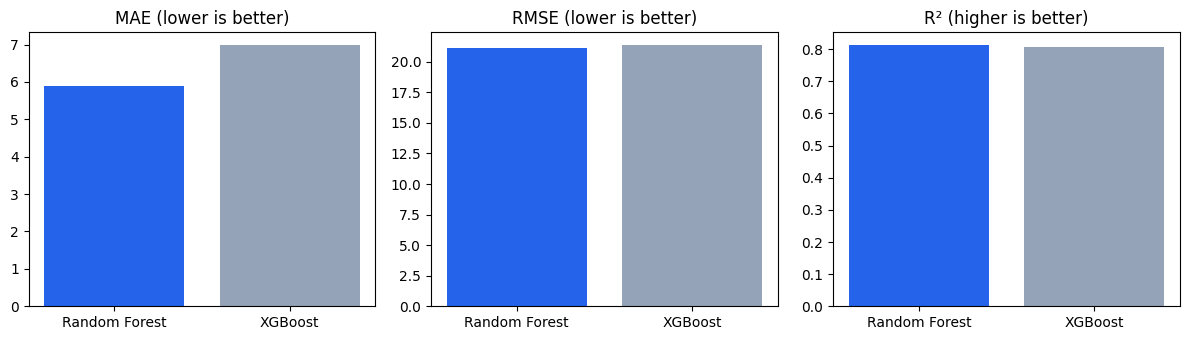

In [10]:
print("Recorded Colab results:")
display(REPORTED_RESULTS)
rf_predictions = rf_model.predict(X_test)
xgb_predictions = xgb_model.predict(X_test)
comparison = pd.DataFrame([
    {"Model": name, "MAE": mean_absolute_error(y_test, predictions),
     "RMSE": np.sqrt(mean_squared_error(y_test, predictions)), "R²": r2_score(y_test, predictions)}
    for name, predictions in [("Random Forest", rf_predictions), ("XGBoost", xgb_predictions)]
]).set_index("Model")
print("Current evaluation (saved artifacts unless RETRAIN=True):")
display(comparison.round(4))
if not RETRAIN:
    np.testing.assert_allclose(comparison.to_numpy(), REPORTED_RESULTS[["MAE", "RMSE", "R²"]].to_numpy(), atol=0.00005, rtol=0)
    print("All six metrics match the recorded rounded values.")
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, metric in zip(axes, ["MAE", "RMSE", "R²"]):
    ax.bar(comparison.index, comparison[metric], color=["#2563eb", "#94a3b8"])
    ax.set_title(metric + (" (higher is better)" if metric == "R²" else " (lower is better)"))
plt.tight_layout(); plt.show()

## 11. Error analysis
The tables show the largest errors and average errors within actual price bands.
The plots compare actual and predicted prices and show residuals. These checks help
identify where the models struggle, especially for expensive vehicles. Price bands are
used only to describe test errors, not to calculate prediction confidence.


,Brand,Model,YOM,Engine (cc),Gear,Fuel Type,Town,Leasing,Condition,AIR CONDITION,POWER STEERING,POWER MIRROR,POWER WINDOW,Actual,RF prediction,XGB prediction,RF absolute error,XGB absolute error
8402,TOYOTA,LEXUS 600HL,2011,600.0,Automatic,Hybrid,Katunayake,No Leasing,USED,Available,Available,Available,Available,790.000,64.412,66.209000,725.588,723.791
6622,TESLA,MODEL 3,2024,573.0,Automatic,Electric,Kelaniya,No Leasing,NEW,Available,Available,Available,Available,347.500,68.036,120.626999,279.464,226.873
6623,TESLA,MODEL 3,2024,1500.0,Automatic,Electric,Nugegoda,No Leasing,USED,Available,Available,Available,Available,375.000,164.613,172.733002,210.387,202.267
8255,TOYOTA,CROWN,2015,2500.0,Automatic,Hybrid,Colombo,No Leasing,USED,Available,Available,Available,Available,316.062,197.015,225.304993,119.048,90.757
2943,NISSAN,FB15 SUPER SALOON,2024,1500.0,Automatic,Petrol,Kurunegala,No Leasing,USED,Available,Available,Available,Available,43.500,138.044,117.438004,94.544,73.938
131,BMW,530E,2017,1500.0,Automatic,Petrol,Kandy,No Leasing,USED,Available,Available,Available,Available,364.500,280.349,290.752014,84.151,73.748
106,BMW,320I E90,2006,2000.0,Manual,Petrol,Colombo,No Leasing,USED,Available,Available,Available,Available,116.000,32.352,74.429001,83.648,41.571
1741,MERCEDES-BENZ,E220 CDI,2017,2200.0,Automatic,Diesel,Colombo,No Leasing,USED,Available,Available,Available,Available,375.000,296.525,270.987000,78.475,104.013
1730,MERCEDES-BENZ,E200,2016,2000.0,Automatic,Petrol,Colombo,No Leasing,USED,Available,Available,Available,Available,405.000,329.122,315.466003,75.878,89.534
132,BMW,530I M SPORT,2017,2200.0,Automatic,Petrol,Colombo,No Leasing,USED,Available,Not_Available,Available,Available,460.000,389.854,359.809998,70.146,100.190


,Count,RF_MAE,XGB_MAE
Price band,,,
0–25,446,3.922,4.847
25–50,609,3.952,4.885
50–100,720,4.747,5.597
100–200,146,11.843,15.096
200+,33,66.722,68.597


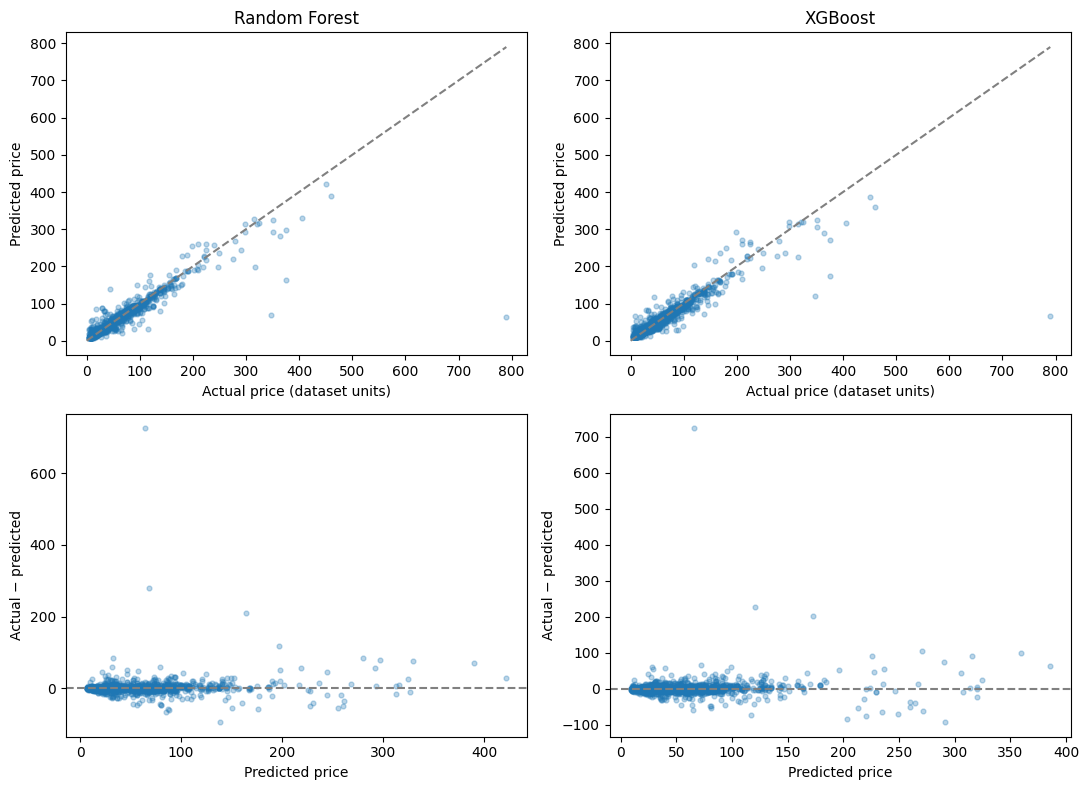

In [11]:
errors = X_test.copy()
errors["Actual"] = y_test
errors["RF prediction"] = rf_predictions
errors["XGB prediction"] = xgb_predictions
errors["RF absolute error"] = abs(y_test - rf_predictions)
errors["XGB absolute error"] = abs(y_test - xgb_predictions)
display(errors.nlargest(10, "RF absolute error").round(3))
errors["Price band"] = pd.cut(y_test, [0, 25, 50, 100, 200, np.inf],
                              labels=["0–25", "25–50", "50–100", "100–200", "200+"])
display(errors.groupby("Price band", observed=True).agg(
    Count=("Actual", "size"), RF_MAE=("RF absolute error", "mean"),
    XGB_MAE=("XGB absolute error", "mean")).round(3))
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for column, (name, predictions) in enumerate([("Random Forest", rf_predictions), ("XGBoost", xgb_predictions)]):
    axes[0, column].scatter(y_test, predictions, s=12, alpha=0.3)
    axes[0, column].plot([0, y_test.max()], [0, y_test.max()], "--", color="grey")
    axes[0, column].set(xlabel="Actual price (dataset units)", ylabel="Predicted price", title=name)
    axes[1, column].scatter(predictions, y_test - predictions, s=12, alpha=0.3)
    axes[1, column].axhline(0, linestyle="--", color="grey")
    axes[1, column].set(xlabel="Predicted price", ylabel="Actual − predicted")
plt.tight_layout(); plt.show()

## 12. Single-sample inference
The reference test record is a Suzuki Celerio ZXI, 2014, 1000 cc, manual, petrol,
listed in Weligama with no leasing, used condition and all four equipment features
available. Its actual listing price is 44.50. Random Forest predicts 33.86 and XGBoost
predicts 30.03. Both underpredict this example; one record cannot establish overall accuracy.


In [12]:
single_vehicle = X_test.iloc[[5]]
assert single_vehicle.iloc[0].to_dict() == REFERENCE
assert np.isclose(y_test.iloc[5], 44.50)
reference_predictions = [float(model.predict(single_vehicle)[0]) for model in [rf_model, xgb_model]]
display(single_vehicle.T)
print("Actual:", y_test.iloc[5], "Predictions:", reference_predictions)
if not RETRAIN:
    np.testing.assert_allclose(reference_predictions, [33.86, 30.03], atol=0.005, rtol=0)
novel = single_vehicle.copy()
novel["Model"] = "__UNSEEN_FOR_ENCODER_TEST__"
assert all(np.isfinite(model.predict(novel)).all() for model in [rf_model, xgb_model])
print("Unseen model category is handled by both encoders; dashboard rejects such entries.")

,4913
Brand,SUZUKI
Model,CELERIO ZXI
YOM,2014
Engine (cc),1000.0
Gear,Manual
Fuel Type,Petrol
Town,Weligama
Leasing,No Leasing
Condition,USED
AIR CONDITION,Available


Actual: 44.5 Predictions: [33.86314644506958, 30.032577514648438]
Unseen model category is handled by both encoders; dashboard rejects such entries.


## 13. Model export and portability
Normal execution loads the submitted models and performs no export. The optional export
cell requires a new training run and writes to a separate timestamped directory. Only
trusted pickle files should be loaded because they can execute code.

The original Colab XGBoost pickle raised `input stream corrupted` on Windows with
XGBoost 3.4.1. Its embedded native Model section was recovered unchanged using
`Booster.load_model`, then exported using `XGBRegressor.save_model`. The original fitted
preprocessor is stored separately. The dashboard loads these portable files.

No trees were retrained or edited. Native export/reload matched all 1,954 recovered test
predictions exactly, and both original pickle hashes remain unchanged. The recovery
script, `models/xgboost_recovery.json` and `VERIFICATION.md` record the checks.
[XGBoost's model IO documentation](https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html)
explains the limitations of pickle snapshots.


In [13]:
if EXPORT_RETRAINED:
    if not RETRAIN:
        raise ValueError("Export requires a separate training run.")
    from datetime import datetime
    export_dir = ROOT / "models" / "retrained" / datetime.now().strftime("%Y%m%d-%H%M%S-%f")
    export_dir.mkdir(parents=True, exist_ok=False)
    for path, model in zip(MODEL_PATHS, [rf_model, xgb_model]):
        output = export_dir / path.name
        joblib.dump(model, output)
        np.testing.assert_allclose(joblib.load(output).predict(single_vehicle), model.predict(single_vehicle))
    print("New run exported to:", export_dir)
else:
    print("Export disabled; original model files are unchanged.")
assert original_hashes == {path.name: sha256(path) for path in MODEL_PATHS}
print("Original model SHA256 values:", original_hashes)

Export disabled; original model files are unchanged.


Original model SHA256 values: {'random_forest_pipeline.pkl': '2afdc136dc5beec5e411cac9932b9469ae6c74fcb5d1690a4cee0cb00a66a17c', 'xgboost_pipeline.pkl': '0724bd41808dc73bc55c19680abb1601481446703378e16927706746e8e01cb7'}


## 14. Discussion of strengths and limitations
Random Forest has lower MAE and RMSE and slightly higher R² in the final experiment.
XGBoost trained faster in the recorded Colab run. The small R² difference has not been
tested for statistical significance. Both pipelines keep preprocessing with prediction
and use the same inputs and test split.

The main limitations are:

- Prices are historical advertised listings, not verified transaction prices. The random
  split does not measure performance in a future market.
- Mileage is derived from year rather than independent odometer readings.
- There are 297 test records sharing all final predictors with a training record.
  Related listings may make random-split results optimistic, although matching attributes
  alone do not prove that listings refer to the same vehicle.
- Some categories are rare or unseen in testing, including 209 test rows with unseen
  model names. One-hot encoding cannot supply learned information about these categories.
- Expensive vehicles have large errors, reflected in RMSE being much higher than MAE.
- The source does not fully explain repeated fractional prices or the currency scale.
- No tuning study, repeated-split uncertainty analysis or calibrated prediction interval
  was performed. Agreement between models does not establish confidence.
- Kaggle states an MIT license; underlying marketplace rights should also be considered
  before redistributing the raw data.

A future study could use verified odometer and transaction data and evaluate grouped or
chronological splits. These would be separate experiments rather than changes to these results.

## 15. Conclusion
Random Forest is the primary model for this class activity because it performs slightly
better on the selected test split. XGBoost provides a useful comparison and had a lower
recorded training time. The dashboard demonstrates both models using 13 features and
original price units. The data-quality findings and large errors limit its use as a
market valuation tool.
